# Lezione 10 — Notebook docente — Caso Aula

## Prompt 0 — inizializzazione e vincoli generali

Caso: **China Evergrande 2021: crisi immobiliare, dipendenza sistemica e controllo della concentrazione creditizia**.

Questo notebook è il prodotto docente pulito e validato. La sequenza rende osservabile la logica normativa:

**Prompt 0 → Prompt 1 → Prompt 2 → Prompt 3 → sei prompt di tappa**.

La Scheda Caso resta la specifica vincolante. Python serve a rendere computabile una specifica teorica già fissata; non modifica stati, matrici, investimenti, LGD, regole di riallocazione, output o controlli. Le proprietà strutturali della simulazione vengono distinte dai controlli numerici.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def draw_next_1d(current, P, rng):
    """Estrae lo stato successivo per molte repliche da una matrice di transizione."""
    u = rng.random(current.shape[0])
    out = np.empty_like(current)
    cdf = np.cumsum(P, axis=1)
    for k in range(P.shape[0]):
        mask = current == k
        if np.any(mask):
            out[mask] = np.searchsorted(cdf[k], u[mask], side="right")
    return out

def draw_next_by_regime(current, regime, matrices, rng):
    """Migrazioni individuali, condizionate a un regime comune per replica."""
    u = rng.random(current.shape)
    out = np.empty_like(current)
    for m, P in enumerate(matrices):
        cdf = np.cumsum(P, axis=1)
        reg_mask = regime == m
        if not np.any(reg_mask):
            continue
        for k in range(P.shape[0]):
            mask = reg_mask[:, None] & (current == k)
            if np.any(mask):
                out[mask] = np.searchsorted(cdf[k], u[mask], side="right")
    return out

def empirical_var_cvar(losses, alpha):
    """
    VaR empirico come quantile sinistro discreto e CVaR coerente con
    CVaR_alpha = q + E[(L-q)_+]/(1-alpha).
    Questa formula gestisce correttamente anche la massa sul VaR.
    """
    x = np.asarray(losses, dtype=float)
    q = np.quantile(x, alpha, method="higher")
    cvar = q + np.maximum(x - q, 0.0).mean() / (1.0 - alpha)
    return float(q), float(cvar)

def risk_summary(losses):
    x = np.asarray(losses, dtype=float)
    v95, c95 = empirical_var_cvar(x, 0.95)
    v99, c99 = empirical_var_cvar(x, 0.99)
    return {
        "Perdita media": x.mean(),
        "Varianza": x.var(ddof=0),
        "Deviazione standard": x.std(ddof=0),
        "VaR 95%": v95,
        "CVaR 95%": c95,
        "VaR 99%": v99,
        "CVaR 99%": c99,
    }

NOTEBOOK_ROLE = "docente"
CASE_ID = "Lezione 10 - Caso Aula - Evergrande"
print(CASE_ID)
print("Ambiente inizializzato; nessun parametro della Scheda Caso viene modificato.")

Lezione 10 - Caso Aula - Evergrande
Ambiente inizializzato; nessun parametro della Scheda Caso viene modificato.


## Prompt 1 — cella iniziale di inquadramento del caso

**Contesto e domanda quantitativa.** Si considera un portafoglio di 36 debitori cinesi, con una posizione Evergrande pari a 30 milioni su un investimento complessivo di 200 milioni. Un regime sistemico comune $M_t\in\{N,S,C\}$ evolve trimestralmente e determina la matrice di migrazione creditizia applicabile. Condizionatamente alla traiettoria sistemica, le migrazioni individuali sono indipendenti. In caso di default la LGD dipende dal regime che governa la transizione nel default.

La domanda è confrontare la distribuzione della perdita a un anno del portafoglio iniziale con quella ottenuta imponendo un limite single-name del 10%, riducendo Evergrande da 30 a 20 milioni e riallocando i 10 milioni liberati **solo** sulle posizioni inizialmente BBB e BB in proporzione agli investimenti iniziali.

**Quantità da stimare/calcolare.**
- Perdita media, varianza e deviazione standard.
- $VaR_{0.95}$, $CVaR_{0.95}$, $VaR_{0.99}$, $CVaR_{0.99}$.
- Probabilità di ingresso almeno una volta nel regime $C$.
- Numero medio di default.
- Perdita media del portafoglio iniziale con e senza ingresso in $C$.
- Differenze $\Delta\rho=\rho(L^P_{\mathrm{lim}})-\rho(L^P_{\mathrm{base}})$.
- Differenza replica per replica $\Delta L^{(r)}=L_{\mathrm{lim}}^{P,(r)}-L_{\mathrm{base}}^{P,(r)}$.

**Output richiesti.**
1. Tabella 1 — portafoglio iniziale.
2. Tabella 2 — portafoglio soggetto al limite.
3. Tabella 3 — misure di rischio e differenze.
4. Tabella 4 — regime sistemico e perdita.
5. Figura 1 — distribuzione del portafoglio iniziale con VaR 95% e 99%.
6. Figura 2 — confronto delle code.
7. Figura 3 — confronto con/senza ingresso in crisi.

**Controlli.** Devono essere coperti i 17 controlli della Scheda Caso: matrici stocastiche, default assorbente, $M_0=S$, traiettoria sistemica unica per replica, estrazioni individuali distinte, primo default, regime corretto per LGD, esclusività migration/default, portafogli a 200, riallocazione vincolata, Common Random Numbers, additività, seed 2027, stabilità Monte Carlo e VaR/CVaR sulle perdite monetarie.

La Scheda Caso è vincolante e non viene modificata.

In [2]:
CASE = {
    "n_debtors": 36,
    "total_investment": 200.0,
    "N_MC": 50_000,
    "T": 4,
    "seed": 2027,
    "system_states": ["N", "S", "C"],
    "credit_states": ["BBB", "BB", "B", "CCC", "D"],
}
display(pd.Series(CASE, name="Specifiche vincolanti"))

n_debtors                             36
total_investment                200.0000
N_MC                               50000
T                                      4
seed                                2027
system_states                  [N, S, C]
credit_states       [BBB, BB, B, CCC, D]
Name: Specifiche vincolanti, dtype: object

## Prompt 2 — Flusso logico-teorico risolutivo validato

| Passo | Finalità risolutiva | Formula / proprietà | Applicazione nel caso | Output o controllo |
|---:|---|---|---|---|
| 1 | Definire portafogli e politica di concentrazione | $V_0^P=200$; limite single-name 10%; riallocazione proporzionale dei 10 milioni su BBB e BB | Costruzione di $V_{\mathrm{base}}$ e $V_{\mathrm{lim}}$ | Tabelle 1–2 e controlli di composizione |
| 2 | Rappresentare il regime sistemico | $M_t\in\{N,S,C\}$, $M_0=S$, matrice $Q$ | Una traiettoria sistemica trimestrale comune | Probabilità di visita a $C$; controlli su $Q$, $M_0$, seed |
| 3 | Modellizzare le migrazioni creditizie | $\Pr(X_{i,t+1}=j\mid X_{i,t}=k,M_t=m)=p_{kj}^{(m)}$; $D$ assorbente | Uso di $P^{(M_t)}$ per 36 debitori | Controlli su matrici, assorbimento e dipendenza |
| 4 | Determinare default e perdite individuali | $\tau_i=\min\{t:X_{i,t}=D\}$; migration loss se $\tau_i>4$; LGD di $M_{\tau_i-1}$ se default | Registrazione primo default e regime di default | Numero default e verifiche LGD/esclusività |
| 5 | Aggregare le perdite | $L^P=\sum_i L_i$; Common Random Numbers | $L^P_{\mathrm{base}}$, $L^P_{\mathrm{lim}}$, $\Delta L$ sulle stesse traiettorie | Distribuzioni empiriche e additività |
| 6 | Stimare rischio e analizzare sistema/politica | media, varianza, $\sigma$, VaR, CVaR | Confronto tra portafogli e condizionamento su visita a $C$ | Tabelle 3–4, Figure 1–3, stabilità |

In [3]:
FLOW_STEPS = pd.DataFrame({
    "Passo": range(1, 7),
    "Nucleo": [
        "Portafogli e concentrazione",
        "Regime sistemico",
        "Migrazioni creditizie",
        "Default e perdite individuali",
        "Aggregazione di portafoglio",
        "Misure di rischio e analisi",
    ],
})
display(FLOW_STEPS)

,Passo,Nucleo
0,1,Portafogli e concentrazione
1,2,Regime sistemico
2,3,Migrazioni creditizie
3,4,Default e perdite individuali
4,5,Aggregazione di portafoglio
5,6,Misure di rischio e analisi


## Prompt 3 — Scomposizione input-output validata

| Tappa | Titolo | Input | Operazione | Output | Controllo | Uso successivo | Regime |
|---:|---|---|---|---|---|---|:---:|
| 1 | Parametri e strutture | $Q$, $P^{(m)}$, $\varphi$, LGD, $N_{MC}$, $T$, seed | Inizializzazione della calibrazione | Strutture dati | righe=1, $D$ assorbente | portafogli e simulazione | B |
| 2 | Due portafogli | composizione, limite 10%, riallocazione | costruire $V_{\mathrm{base}},V_{\mathrm{lim}}$ | Tabelle 1–2 | totale 200, Evergrande 20, 10 solo BBB/BB | perdite monetarie | B |
| 3 | Traiettorie | seed, $M_0$, $Q$, $P^{(m)}$, rating iniziali | simulare regime comune, rating e $\tau$ | $M,X,\tau$, regime di default | primo $D$, assorbimento, proprietà per costruzione | perdite | B |
| 4 | Perdite | traiettorie, investimenti, $\varphi$, LGD | applicare migration loss o LGD e aggregare | $L_{\mathrm{base}},L_{\mathrm{lim}},\Delta L$ | LGD corretta, esclusività, CRN, additività | rischio | B |
| 5 | Rischio e condizionamento | campioni di perdita, $M$ | statistiche, VaR/CVaR, condizionamento | Tabelle 3–4 | calcolo monetario e stabilità | grafici | B |
| 6 | Grafici e controlli finali | tutti gli output | Figure 1–3 e ricognizione controlli | grafici + sintesi controlli | copertura completa e coerenza | interpretazione docente | B |

In [4]:
STAGES = [
    "Parametri e strutture del modello",
    "Costruzione dei due portafogli",
    "Simulazione delle traiettorie sistemiche e creditizie",
    "Perdite individuali e di portafoglio",
    "Misure di rischio e analisi condizionata",
    "Rappresentazione grafica e controlli conclusivi",
]
display(pd.DataFrame({"Tappa": range(1, 7), "Titolo": STAGES}))

,Tappa,Titolo
0,1,Parametri e strutture del modello
1,2,Costruzione dei due portafogli
2,3,Simulazione delle traiettorie sistemiche e cre...
3,4,Perdite individuali e di portafoglio
4,5,Misure di rischio e analisi condizionata
5,6,Rappresentazione grafica e controlli conclusivi


## Prompt di tappa 1 — Parametri e strutture del modello (Regime B)

**Input:** $Q$, $P^{(N)}$, $P^{(S)}$, $P^{(C)}$, tabella $\varphi$, LGD per regime, $N_{MC}=50\,000$, $T=4$, seed 2027.

**Operazione:** tradurre fedelmente la calibrazione in NumPy/Pandas.

**Output:** strutture dati riutilizzabili.

**Controlli:** somme di riga pari a 1; stato $D$ assorbente. Questi sono controlli numerici/formali preliminari.

In [5]:
system_states = ["N", "S", "C"]
credit_states = ["BBB", "BB", "B", "CCC", "D"]

Q = np.array([
    [0.84, 0.15, 0.01],
    [0.20, 0.62, 0.18],
    [0.08, 0.30, 0.62],
])

P_N = np.array([
    [0.955, 0.038, 0.005, 0.001, 0.001],
    [0.025, 0.925, 0.038, 0.009, 0.003],
    [0.005, 0.035, 0.885, 0.060, 0.015],
    [0.001, 0.004, 0.025, 0.900, 0.070],
    [0, 0, 0, 0, 1],
])
P_S = np.array([
    [0.925, 0.060, 0.011, 0.003, 0.001],
    [0.012, 0.875, 0.085, 0.022, 0.006],
    [0.003, 0.020, 0.810, 0.135, 0.032],
    [0, 0.003, 0.022, 0.855, 0.120],
    [0, 0, 0, 0, 1],
])
P_C = np.array([
    [0.830, 0.115, 0.035, 0.015, 0.005],
    [0.004, 0.745, 0.145, 0.075, 0.031],
    [0, 0.008, 0.650, 0.242, 0.100],
    [0, 0, 0.008, 0.692, 0.300],
    [0, 0, 0, 0, 1],
])
P_regime = [P_N, P_S, P_C]

phi = np.array([
    [0.00, 0.04, 0.11, 0.26],
    [-0.03, 0.00, 0.07, 0.19],
    [-0.07, -0.04, 0.00, 0.13],
    [-0.12, -0.08, -0.04, 0.00],
])
lgd = np.array([0.55, 0.70, 0.85])

N_MC, T, SEED = 50_000, 4, 2027

row_checks = {
    "Q": np.allclose(Q.sum(axis=1), 1),
    "P_N": np.allclose(P_N.sum(axis=1), 1),
    "P_S": np.allclose(P_S.sum(axis=1), 1),
    "P_C": np.allclose(P_C.sum(axis=1), 1),
}
absorbing = all(np.allclose(P[-1], [0,0,0,0,1]) for P in P_regime)
display(pd.Series(row_checks, name="Somme di riga = 1"))
print("D assorbente in tutte le P:", absorbing)
assert all(row_checks.values()) and absorbing

Q      True
P_N    True
P_S    True
P_C    True
Name: Somme di riga = 1, dtype: bool

D assorbente in tutte le P: True


## Prompt di tappa 2 — Costruzione dei due portafogli (Regime B)

**Input:** composizione iniziale, $V_0^P=200$, Evergrande 30, limite del 10%, riallocazione dei 10 milioni esclusivamente sui gruppi BBB e BB.

**Operazione:** costruire i vettori monetari base e limitato, preservando il totale e la proporzione 60:50 tra i gruppi destinatari.

**Output:** Tabelle 1 e 2; $V_{\mathrm{base}}$, $V_{\mathrm{lim}}$.

**Controlli:** totale 200 in entrambi; Evergrande 20 nel secondo; riallocazione esattamente 10; nessun incremento per B/CCC; rapporto BBB/BB preservato.

In [6]:
names = (["China Evergrande Group"] +
         [f"BBB_{i+1:02d}" for i in range(10)] +
         [f"BB_{i+1:02d}" for i in range(10)] +
         [f"B_{i+1:02d}" for i in range(10)] +
         [f"CCC_{i+1:02d}" for i in range(5)])
rating0 = np.array([2] + [0]*10 + [1]*10 + [2]*10 + [3]*5, dtype=np.int8)
V_base = np.array([30] + [6]*10 + [5]*10 + [4]*10 + [4]*5, dtype=float)
V_lim = V_base.copy()
V_lim[0] = 20.0
V_lim[1:11] += 10.0 * 6.0 / 110.0
V_lim[11:21] += 10.0 * 5.0 / 110.0

portfolio = pd.DataFrame({
    "Debitore": names,
    "Rating iniziale": np.array(credit_states)[rating0],
    "Base": V_base,
    "Limite 10%": V_lim,
})

tab1 = (portfolio.groupby("Rating iniziale", sort=False)
        .agg(N=("Debitore","size"), Investimento_individuale=("Base","first"),
             Investimento_complessivo=("Base","sum")))
tab2 = (portfolio.groupby("Rating iniziale", sort=False)
        .agg(N=("Debitore","size"), Investimento_individuale=("Limite 10%","first"),
             Investimento_complessivo=("Limite 10%","sum")))

print("Tabella 1 — Portafoglio iniziale")
display(tab1)
print("Tabella 2 — Portafoglio soggetto al limite")
display(tab2)

assert np.isclose(V_base.sum(), 200)
assert np.isclose(V_lim.sum(), 200)
assert np.isclose(V_lim[0], 20)
assert np.isclose((V_lim - V_base).sum(), 0)
assert np.isclose((V_lim[1:] - V_base[1:]).sum(), 10)
assert np.allclose(V_lim[21:], V_base[21:])
assert np.isclose(V_lim[1:11].sum()/V_lim[11:21].sum(), 60/50)
print("Controlli di portafoglio: OK")

Tabella 1 — Portafoglio iniziale


,N,Investimento_individuale,Investimento_complessivo
Rating iniziale,,,
B,11,30.0000,70.0000
BBB,10,6.0000,60.0000
BB,10,5.0000,50.0000
CCC,5,4.0000,20.0000


Tabella 2 — Portafoglio soggetto al limite


,N,Investimento_individuale,Investimento_complessivo
Rating iniziale,,,
B,11,20.0000,60.0000
BBB,10,6.5455,65.4545
BB,10,5.4545,54.5455
CCC,5,4.0000,20.0000


Controlli di portafoglio: OK


## Prompt di tappa 3 — Simulazione delle traiettorie sistemiche e creditizie (Regime B)

**Input:** seed 2027, $N_{MC}=50\,000$, $T=4$, $M_0=S$, $Q$, $P^{(m)}$, rating iniziali.

**Operazione:** per ogni replica simulare una sola traiettoria sistemica comune; quindi, condizionatamente a $M_t$, migrazioni individuali distinte. Registrare il primo ingresso in $D$, il tempo $\tau_i$ e il regime che governa la transizione nel default.

**Output:** traiettorie sistemiche, rating finali, $\tau_i$, regime di default.

**Controlli:** $M_0=S$; primo ingresso corretto; $D$ assorbente. Traiettoria sistemica unica e indipendenza condizionata sono proprietà **PER COSTRUZIONE** dell'algoritmo.

In [7]:
rng = np.random.default_rng(SEED)

# Regime sistemico: una traiettoria per replica.
M_sim = np.empty((N_MC, T), dtype=np.int8)
M_sim[:, 0] = 1  # S
for t in range(T-1):
    M_sim[:, t+1] = draw_next_1d(M_sim[:, t], Q, rng)

# Rating dei 36 debitori e registrazione del primo default.
X_sim = np.tile(rating0, (N_MC, 1)).astype(np.int8)
tau = np.full((N_MC, len(rating0)), T+1, dtype=np.int8)
default_regime = np.full_like(tau, -1)

for t in range(T):
    X_next = draw_next_by_regime(X_sim, M_sim[:, t], P_regime, rng)
    newly_default = (X_sim != 4) & (X_next == 4)
    tau[newly_default] = t + 1
    reg_matrix = np.broadcast_to(M_sim[:, t, None], X_sim.shape)
    default_regime[newly_default] = reg_matrix[newly_default]
    X_sim = X_next

assert np.all(M_sim[:, 0] == 1)
assert np.all((X_sim >= 0) & (X_sim < 5))
assert np.all((M_sim >= 0) & (M_sim < 3))
assert np.all((tau <= T) == (X_sim == 4))

print("Shape regimi:", M_sim.shape)
print("Shape rating finali:", X_sim.shape)
print("Seed impostato:", SEED)
print("Traiettoria sistemica unica per replica: PER COSTRUZIONE")
print("Estrazioni individuali distinte condizionate al regime: PER COSTRUZIONE")
print("Default assorbente e primo ingresso: OK")

Shape regimi: (50000, 4)
Shape rating finali: (50000, 36)
Seed impostato: 2027
Traiettoria sistemica unica per replica: PER COSTRUZIONE
Estrazioni individuali distinte condizionate al regime: PER COSTRUZIONE
Default assorbente e primo ingresso: OK


## Prompt di tappa 4 — Perdite individuali e di portafoglio (Regime B)

**Input:** $M$, $X$, $\tau$, $V_{\mathrm{base}}$, $V_{\mathrm{lim}}$, $\varphi$, LGD per regime.

**Operazione:** se $\tau_i>4$ applicare esclusivamente $\varphi(X_{i,0},X_{i,4})$; se $\tau_i\le4$ applicare esclusivamente $\mathrm{LGD}^{(M_{\tau_i-1})}$. Riutilizzare gli stessi tassi di perdita realizzati per i due vettori di investimento.

**Output:** perdite individuali, $L^P_{\mathrm{base}}$, $L^P_{\mathrm{lim}}$, $\Delta L$, numero default.

**Controlli:** LGD corretta sull'intero insieme dei default; esclusività migration/default; Common Random Numbers **PER COSTRUZIONE**; additività replica per replica.

In [8]:
n_debtors = len(rating0)
initial_matrix = np.broadcast_to(rating0, (N_MC, n_debtors))
is_default = tau <= T
loss_rate = np.empty((N_MC, n_debtors), dtype=float)

# Default: LGD del regime che governa la transizione verso D.
loss_rate[is_default] = lgd[default_regime[is_default]]

# Sopravvissuti: perdita migration-based tra rating iniziale e finale.
survive = ~is_default
loss_rate[survive] = phi[initial_matrix[survive], X_sim[survive]]

L_ind_base = loss_rate * V_base
L_ind_lim = loss_rate * V_lim
L_base = L_ind_base.sum(axis=1)
L_lim = L_ind_lim.sum(axis=1)
delta_L = L_lim - L_base
n_defaults = is_default.sum(axis=1)

# Verifiche globali.
expected_default_rate = lgd[default_regime[is_default]]
assert np.allclose(loss_rate[is_default], expected_default_rate)
assert np.allclose(loss_rate[survive], phi[initial_matrix[survive], X_sim[survive]])
assert np.allclose(L_base, L_ind_base.sum(axis=1))
assert np.allclose(L_lim, L_ind_lim.sum(axis=1))
assert np.allclose(delta_L, L_lim - L_base)

print("LGD corretta per tutti i default: OK")
print("Esclusività migration/default: OK")
print("Common Random Numbers: PER COSTRUZIONE (stesso loss_rate per i due portafogli)")
print("Additività delle perdite per ogni replica: OK")

LGD corretta per tutti i default: OK
Esclusività migration/default: OK
Common Random Numbers: PER COSTRUZIONE (stesso loss_rate per i due portafogli)
Additività delle perdite per ogni replica: OK


## Prompt di tappa 5 — Misure di rischio e analisi condizionata (Regime B)

**Input:** $L^P_{\mathrm{base}}$, $L^P_{\mathrm{lim}}$, $\Delta L$, traiettorie sistemiche.

**Operazione:** calcolare statistiche descrittive e misure di coda sulle perdite monetarie. Il CVaR empirico usa la definizione quantile-based

$$
CVaR_\alpha=q_\alpha+\frac{1}{1-\alpha}\,\mathbb E[(L-q_\alpha)_+],
$$

che gestisce correttamente la massa sul VaR nelle distribuzioni empiriche discrete.

**Output:** Tabelle 3 e 4; probabilità di visita a $C$; numero medio di default; differenze $\Delta\rho$.

**Controllo:** confronto campione completo / prime 25.000 repliche come verifica empirica di stabilità, non come dimostrazione di convergenza.

In [9]:
s_base = risk_summary(L_base)
s_lim = risk_summary(L_lim)
risk_table = pd.DataFrame({"Base": s_base, "Limite 10%": s_lim})
risk_table["Delta (lim-base)"] = risk_table["Limite 10%"] - risk_table["Base"]

hit_C = (M_sim == 2).any(axis=1)
system_table = pd.DataFrame({
    "Gruppo repliche": ["Senza ingresso in C", "Con ingresso in C"],
    "Numero repliche": [(~hit_C).sum(), hit_C.sum()],
    "Perdita media base": [L_base[~hit_C].mean(), L_base[hit_C].mean()],
})

print("Tabella 3 — Misure di rischio")
display(risk_table)
print("Tabella 4 — Regime sistemico e perdita")
display(system_table)

print(f"Probabilità di ingresso in C: {hit_C.mean():.4%}")
print(f"Numero medio di default: {n_defaults.mean():.4f}")

half = 25_000
stable = pd.DataFrame({
    "Base completo": risk_summary(L_base),
    "Base prime 25k": risk_summary(L_base[:half]),
    "Limite completo": risk_summary(L_lim),
    "Limite prime 25k": risk_summary(L_lim[:half]),
})
print("Controllo empirico di stabilità")
display(stable.loc[["Perdita media","Deviazione standard","VaR 95%","CVaR 95%","VaR 99%","CVaR 99%"]])

Tabella 3 — Misure di rischio


,Base,Limite 10%,Delta (lim-base)
Perdita media,26.1996,24.9050,-1.2945
Varianza,277.0019,226.2906,-50.7113
Deviazione standard,16.6434,15.0430,-1.6004
VaR 95%,60.7500,55.5273,-5.2227
CVaR 95%,69.2909,63.3568,-5.9341
VaR 99%,74.5400,68.2255,-6.3145
CVaR 99%,79.9198,73.8267,-6.0931


Tabella 4 — Regime sistemico e perdita


,Gruppo repliche,Numero repliche,Perdita media base
0,Senza ingresso in C,31427,17.5016
1,Con ingresso in C,18573,40.9173


Probabilità di ingresso in C: 37.1460%
Numero medio di default: 5.3564
Controllo empirico di stabilità


,Base completo,Base prime 25k,Limite completo,Limite prime 25k
Perdita media,26.1996,26.1871,24.9050,24.8882
Deviazione standard,16.6434,16.6046,15.0430,15.0031
VaR 95%,60.7500,60.7600,55.5273,55.3891
CVaR 95%,69.2909,69.3605,63.3568,63.4211
VaR 99%,74.5400,74.6900,68.2255,68.4364
CVaR 99%,79.9198,80.2763,73.8267,74.1872


## Prompt di tappa 6 — Rappresentazione grafica e controlli conclusivi (Regime B)

**Input:** distribuzioni simulate, $\Delta L$, indicatore di ingresso in crisi e risultati precedenti.

**Operazione:** generare le tre figure richieste e ricostruire l'esito dei controlli, distinguendo verifiche numeriche da proprietà strutturali **PER COSTRUZIONE**.

**Output:** Figure 1–3 e sintesi finale dei controlli.

**Controllo:** coerenza fra grafici, tabelle e campioni numerici.

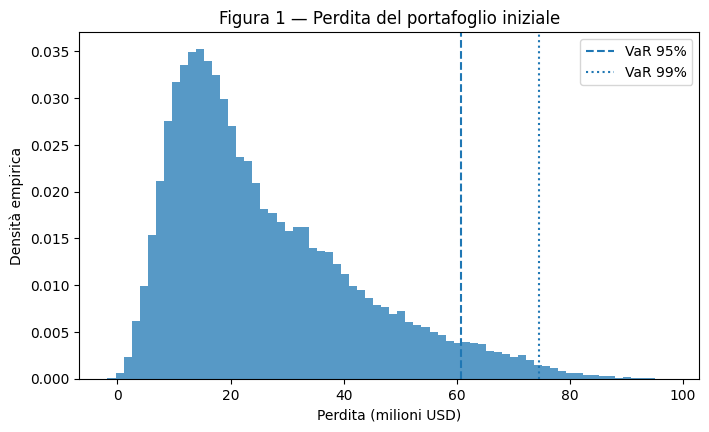

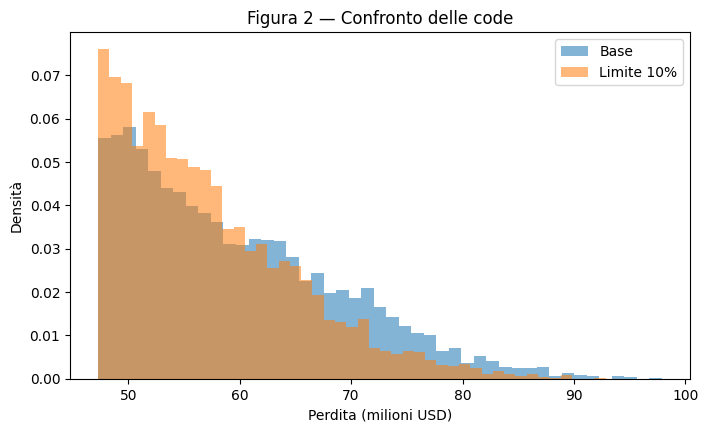

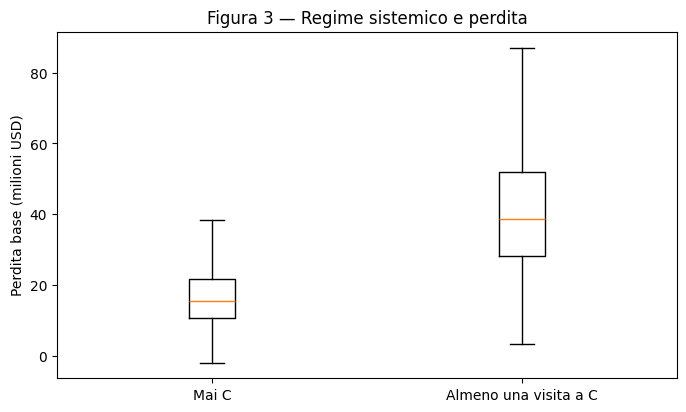

,Esito
Q e P con righe che sommano a 1,True
D assorbente,True
M0=S,True
Primo default coerente con stato finale D,True
LGD del regime di transizione nel default,True
Migration loss solo sui sopravvissuti,True
Totale investito base=200,True
Totale investito limite=200,True
Evergrande limite=20,True
Riallocazione vincolata a BBB/BB,True


In [10]:
# Figura 1
fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(L_base, bins=70, density=True, alpha=0.75)
ax.axvline(s_base["VaR 95%"], linestyle="--", label="VaR 95%")
ax.axvline(s_base["VaR 99%"], linestyle=":", label="VaR 99%")
ax.set(title="Figura 1 — Perdita del portafoglio iniziale",
       xlabel="Perdita (milioni USD)", ylabel="Densità empirica")
ax.legend()
plt.show()

# Figura 2 — attenzione alla coda destra
cut = min(np.quantile(L_base, .90), np.quantile(L_lim, .90))
fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(L_base[L_base >= cut], bins=45, density=True, alpha=0.55, label="Base")
ax.hist(L_lim[L_lim >= cut], bins=45, density=True, alpha=0.55, label="Limite 10%")
ax.set(title="Figura 2 — Confronto delle code", xlabel="Perdita (milioni USD)", ylabel="Densità")
ax.legend()
plt.show()

# Figura 3
fig, ax = plt.subplots(figsize=(8,4.5))
ax.boxplot([L_base[~hit_C], L_base[hit_C]], tick_labels=["Mai C", "Almeno una visita a C"], showfliers=False)
ax.set(title="Figura 3 — Regime sistemico e perdita", ylabel="Perdita base (milioni USD)")
plt.show()

controls = pd.Series({
    "Q e P con righe che sommano a 1": all(row_checks.values()),
    "D assorbente": absorbing,
    "M0=S": bool(np.all(M_sim[:,0] == 1)),
    "Primo default coerente con stato finale D": bool(np.all((tau <= T) == (X_sim == 4))),
    "LGD del regime di transizione nel default": bool(np.allclose(loss_rate[is_default], lgd[default_regime[is_default]])),
    "Migration loss solo sui sopravvissuti": bool(np.allclose(loss_rate[survive], phi[initial_matrix[survive], X_sim[survive]])),
    "Totale investito base=200": bool(np.isclose(V_base.sum(), 200)),
    "Totale investito limite=200": bool(np.isclose(V_lim.sum(), 200)),
    "Evergrande limite=20": bool(np.isclose(V_lim[0], 20)),
    "Riallocazione vincolata a BBB/BB": bool(np.allclose(V_lim[21:], V_base[21:])),
    "Additività base": bool(np.allclose(L_base, L_ind_base.sum(1))),
    "Additività limite": bool(np.allclose(L_lim, L_ind_lim.sum(1))),
    "Seed configurato=2027": SEED == 2027,
    "CRN": "PER COSTRUZIONE",
    "Traiettoria sistemica unica": "PER COSTRUZIONE",
    "Indipendenza condizionata": "PER COSTRUZIONE",
    "Stabilità MC": "VERIFICA EMPIRICA riportata sopra",
})
display(controls.to_frame("Esito"))

## Interpretazione docente di riferimento e limiti

I risultati mostrano che il regime sistemico comune è economicamente rilevante: le repliche che visitano lo stato di crisi presentano una perdita media nettamente superiore. La politica di concentrazione riduce la posizione Evergrande mantenendo invariato l'investimento complessivo e, con la calibrazione assegnata, riduce sia la dispersione sia le principali misure di coda; l'effetto è più marcato su VaR/CVaR che sulla perdita media.

Il confronto non implica dominanza replica per replica: $\Delta L$ può assumere anche valori positivi perché l'importo liberato viene reinvestito. Le conclusioni valgono per il modello didattico assegnato: matrici, LGD e investimenti sono calibrati a fini didattici e non costituiscono una ricostruzione empirica o una previsione storica della crisi Evergrande.

In [11]:
benchmark = pd.DataFrame({
    "Output notebook": [
        s_base["Perdita media"], s_base["Deviazione standard"], s_base["VaR 95%"],
        s_base["CVaR 95%"], s_base["VaR 99%"], s_base["CVaR 99%"],
        s_lim["Perdita media"], s_lim["Deviazione standard"], s_lim["VaR 95%"],
        s_lim["CVaR 95%"], s_lim["VaR 99%"], s_lim["CVaR 99%"],
    ],
    "Benchmark indicativo scheda": [
        26.20,16.64,60.74,69.29,74.51,79.92,
        24.91,15.04,55.52,63.36,68.20,73.83,
    ],
}, index=[
    "Base media","Base sd","Base VaR95","Base CVaR95","Base VaR99","Base CVaR99",
    "Lim media","Lim sd","Lim VaR95","Lim CVaR95","Lim VaR99","Lim CVaR99"
])
benchmark["Scarto"] = benchmark["Output notebook"] - benchmark["Benchmark indicativo scheda"]
display(benchmark)
print("Calibrazione coerente con i valori indicativi della Scheda Costruzione.")

,Output notebook,Benchmark indicativo scheda,Scarto
Base media,26.1996,26.2000,-0.0004
Base sd,16.6434,16.6400,0.0034
Base VaR95,60.7500,60.7400,0.0100
Base CVaR95,69.2909,69.2900,0.0009
Base VaR99,74.5400,74.5100,0.0300
Base CVaR99,79.9198,79.9200,-0.0002
Lim media,24.9050,24.9100,-0.0050
Lim sd,15.0430,15.0400,0.0030
Lim VaR95,55.5273,55.5200,0.0073
Lim CVaR95,63.3568,63.3600,-0.0032


Calibrazione coerente con i valori indicativi della Scheda Costruzione.
